In [1]:
import pandas as pd

# Load the heart disease dataset
df = pd.read_csv("heart.csv")

# Basic dataset information
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["target"].value_counts())


Dataset shape: (1025, 14)

Column names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

First 5 rows:
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
tar

## Step 2: Separating the Features and Target

The selected paper uses 14 attributes in the heart disease dataset, including the target variable. The target represents the prediction outcome, where 0 indicates no heart disease and 1 indicates the presence of heart disease.

To reproduce this setup, I separated the dataset into input features (X) and the target (y). The target column was removed from X, leaving the remaining 13 patient attributes as the features used to train the machine learning models.

In [2]:
# Separate input features and target
X = df.drop("target", axis=1)
y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature shape: (1025, 13)
Target shape: (1025,)

Target distribution:
target
1    526
0    499
Name: count, dtype: int64


## Step 3: Splitting the Dataset into Training and Testing Sets

The paper states that after preprocessing, the dataset is divided into training and testing sets for model development and evaluation. The training data is used to build the classification models, while the testing data is used to evaluate their predictions.

The paper does not clearly specify all implementation details required to recreate the exact split. Therefore, for this reproduction, I used an 80:20 train-test split. I also used a fixed random state so that the same split can be reproduced when the notebook is run again. Stratification was applied to maintain a similar distribution of the target classes in both sets.

These settings are documented as reproduction assumptions rather than settings reported by the original authors.

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (820, 13)
Testing features: (205, 13)

Training target distribution:
target
1    421
0    399
Name: count, dtype: int64

Testing target distribution:
target
1    105
0    100
Name: count, dtype: int64


## Step 4: Feature Scaling

The preprocessing section of the selected paper states that numerical attributes are normalised so that their values are brought to a similar scale. The authors explain that this is performed without losing information and is intended to reduce the complexity and processing cost of the machine learning algorithms.

To reproduce the scaling stage, I applied feature scaling after the train-test split. The scaler was fitted using the training data and the same fitted transformation was then applied to the testing data.

In [4]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Before scaling:")
print(X_train.head())

print("\nAfter scaling:")
print(X_train_scaled[:5])

Before scaling:
     age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  \
4     62    0   0       138   294    1        1      106      0      1.9   
688   56    0   0       200   288    1        0      133      1      4.0   
477   57    1   2       128   229    0        0      150      0      0.4   
336   57    1   2       150   126    1        1      173      0      0.2   
960   52    0   2       136   196    0        0      169      0      0.1   

     slope  ca  thal  
4        1   3     2  
688      0   2     3  
477      1   1     3  
336      2   1     3  
960      1   0     2  

After scaling:
[[ 0.81162633 -1.50996689 -0.90957214  0.31472862  0.89579058  2.34689934
   0.926946   -1.92115501 -0.71813066  0.69652503 -0.59754229  2.20730061
  -0.56245085]
 [ 0.15224695 -1.50996689 -0.90957214  3.76764257  0.77911537  2.34689934
  -0.98284224 -0.72536159  1.39250426  2.47581015 -2.1987994   1.22840039
   1.0906305 ]
 [ 0.26214351  0.66226618  1.04803719 -0.242192


The selected paper describes preprocessing as handling missing values, scaling the numerical attributes, and encoding categorical variables before model development.

For the dataset used in my reproduction, the initial inspection showed no missing values, so no missing-value imputation was required. The categorical attributes were also already represented numerically in the downloaded dataset. Therefore, I retained their existing representation rather than encoding them again.

Feature scaling was applied to reproduce the scaling stage described in the paper. The scaler was fitted using the training data and the same transformation was then applied to the testing data. This completed the main preprocessing stage before training the classification models.



After preprocessing, the selected paper evaluates six individual classification methods: Logistic Regression, Decision Tree, Random Forest, Extreme Gradient Boosting (XGBoost), Naive Bayes, and K-Nearest Neighbours (KNN).

I reproduced these classifiers individually before implementing the proposed stacking model. This allows the reproduced performance of each classifier to be compared with the results reported in the original paper.

For evaluation, I used Accuracy, Precision, Recall, F1 Score, and AUC, as required by the task sheet and reported in the paper's experimental results.


Logistic Regression is the first individual classifier reproduced from the selected paper. The model was trained using the preprocessed training data and then evaluated using the unseen testing data.

The reproduced model is evaluated using Accuracy, Precision, Recall, F1 Score, and AUC so that its performance can later be directly compared with the results reported in the paper. According to Table 11 of the selected paper, Logistic Regression achieved an accuracy of 0.8439, precision of 0.8196, recall of 0.9090, F1 score of 0.8620, and AUC of 0.9204.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score

# Create and train the Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)

lr_model.fit(X_train_scaled, y_train)

# Make predictions on the test data
lr_predictions = lr_model.predict(X_test_scaled)

# Probability predictions for AUC
lr_probabilities = lr_model.predict_proba(X_test_scaled)[:, 1]

# Calculate evaluation metrics
lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(y_test, lr_predictions)
lr_recall = recall_score(y_test, lr_predictions)
lr_f1 = f1_score(y_test, lr_predictions)
lr_auc = roc_auc_score(y_test, lr_probabilities)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))
print("AUC      :", round(lr_auc, 4))

Logistic Regression Results
---------------------------
Accuracy : 0.8098
Precision: 0.7619
Recall   : 0.9143
F1 Score : 0.8312
AUC      : 0.9298


### Duplicate Record Check

As an additional dataset inspection step, I checked for exact duplicated rows in the downloaded dataset. The dataset contains 1,025 records, which matches the number of patients reported in the selected paper.

The duplicate check identified 723 rows as exact duplicates, leaving 302 unique rows. However, the preprocessing methodology described in the paper does not state that duplicate records were removed. Removing them would also reduce the dataset from the reported 1,025 observations to 302 observations.

Therefore, I retained all 1,025 records for the Part 1 reproduction so that the dataset size remains consistent with the study. The presence of duplicate records is documented as an observation and will be considered when critically analysing the experimental methodology.

In [6]:
# Check for duplicated rows
duplicate_count = df.duplicated().sum()

print("Total rows:", len(df))
print("Duplicated rows:", duplicate_count)
print("Unique rows:", len(df.drop_duplicates()))

Total rows: 1025
Duplicated rows: 723
Unique rows: 302


### 5.2 Naive Bayes

Naive Bayes is the second individual classifier reproduced from the selected paper. I trained the model using the same prepared training data and evaluated it using the same testing set so that its performance could be compared fairly with the other classifiers.

Table 11 of the paper reports a Naive Bayes accuracy of 0.8439, precision of 0.8250, recall of 0.9000, F1 score of 0.8608, and AUC of 0.9185. I calculated the same five evaluation metrics for my reproduced model to allow a direct comparison with the published results.

In [7]:
from sklearn.naive_bayes import GaussianNB

# Create and train the Naive Bayes model
nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

# Make predictions
nb_predictions = nb_model.predict(X_test_scaled)

# Probability predictions for AUC
nb_probabilities = nb_model.predict_proba(X_test_scaled)[:, 1]

# Calculate evaluation metrics
nb_accuracy = accuracy_score(y_test, nb_predictions)
nb_precision = precision_score(y_test, nb_predictions)
nb_recall = recall_score(y_test, nb_predictions)
nb_f1 = f1_score(y_test, nb_predictions)
nb_auc = roc_auc_score(y_test, nb_probabilities)

print("Naive Bayes Results")
print("-------------------")
print("Accuracy :", round(nb_accuracy, 4))
print("Precision:", round(nb_precision, 4))
print("Recall   :", round(nb_recall, 4))
print("F1 Score :", round(nb_f1, 4))
print("AUC      :", round(nb_auc, 4))

Naive Bayes Results
-------------------
Accuracy : 0.8293
Precision: 0.807
Recall   : 0.8762
F1 Score : 0.8402
AUC      : 0.9043


###  K-Nearest Neighbours (KNN)

The next classifier reproduced from the selected paper is K-Nearest Neighbours (KNN). As with the previous models, I trained and evaluated KNN using the same prepared training and testing data to maintain a consistent experimental setup.

According to Table 11 of the paper, KNN achieved an accuracy of 0.8585, precision of 0.8648, recall of 0.8727, F1 score of 0.8687, and AUC of 0.9304. I calculated the same metrics for my reproduced KNN model so that its performance can later be directly compared with the published results.

In [8]:
from sklearn.neighbors import KNeighborsClassifier

# Create and train the KNN model
knn_model = KNeighborsClassifier()

knn_model.fit(X_train_scaled, y_train)

# Make predictions
knn_predictions = knn_model.predict(X_test_scaled)

# Probability predictions for AUC
knn_probabilities = knn_model.predict_proba(X_test_scaled)[:, 1]

# Calculate evaluation metrics
knn_accuracy = accuracy_score(y_test, knn_predictions)
knn_precision = precision_score(y_test, knn_predictions)
knn_recall = recall_score(y_test, knn_predictions)
knn_f1 = f1_score(y_test, knn_predictions)
knn_auc = roc_auc_score(y_test, knn_probabilities)

print("KNN Results")
print("-----------")
print("Accuracy :", round(knn_accuracy, 4))
print("Precision:", round(knn_precision, 4))
print("Recall   :", round(knn_recall, 4))
print("F1 Score :", round(knn_f1, 4))
print("AUC      :", round(knn_auc, 4))

KNN Results
-----------
Accuracy : 0.8634
Precision: 0.8738
Recall   : 0.8571
F1 Score : 0.8654
AUC      : 0.9629


###Decision Tree

The fourth individual classifier reproduced from the selected paper is the Decision Tree. I trained and tested the model using the same training and testing data used for the previous classifiers so that the experimental setup remained consistent.

According to Table 11 of the selected paper, the Decision Tree achieved an accuracy of 0.9268, precision of 0.9702, recall of 0.8909, F1 score of 0.9289, and AUC of 0.9702. The same five metrics were calculated for my reproduced Decision Tree model for later comparison with the published results.

In [9]:
from sklearn.tree import DecisionTreeClassifier

# Create and train the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_scaled, y_train)

# Make predictions
dt_predictions = dt_model.predict(X_test_scaled)

# Probability predictions for AUC
dt_probabilities = dt_model.predict_proba(X_test_scaled)[:, 1]

# Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test, dt_predictions)
dt_precision = precision_score(y_test, dt_predictions)
dt_recall = recall_score(y_test, dt_predictions)
dt_f1 = f1_score(y_test, dt_predictions)
dt_auc = roc_auc_score(y_test, dt_probabilities)

print("Decision Tree Results")
print("---------------------")
print("Accuracy :", round(dt_accuracy, 4))
print("Precision:", round(dt_precision, 4))
print("Recall   :", round(dt_recall, 4))
print("F1 Score :", round(dt_f1, 4))
print("AUC      :", round(dt_auc, 4))

Decision Tree Results
---------------------
Accuracy : 0.9854
Precision: 1.0
Recall   : 0.9714
F1 Score : 0.9855
AUC      : 0.9857


### Random Forest

The fifth individual classifier reproduced from the selected paper is Random Forest. The model was trained and evaluated using the same prepared training and testing data as the previous classifiers to keep the reproduction procedure consistent.

According to Table 11 of the selected paper, Random Forest achieved an accuracy of 0.9268, precision of 0.9130, recall of 0.9545, F1 score of 0.9333, and AUC of 0.9734. I calculated the same five evaluation metrics for my reproduced Random Forest model so that the results can later be directly compared with the published findings.

In [10]:
from sklearn.ensemble import RandomForestClassifier

# Create and train the Random Forest model
rf_model = RandomForestClassifier(random_state=42)

rf_model.fit(X_train_scaled, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test_scaled)

# Probability predictions for AUC
rf_probabilities = rf_model.predict_proba(X_test_scaled)[:, 1]

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, rf_predictions)
rf_precision = precision_score(y_test, rf_predictions)
rf_recall = recall_score(y_test, rf_predictions)
rf_f1 = f1_score(y_test, rf_predictions)
rf_auc = roc_auc_score(y_test, rf_probabilities)

print("Random Forest Results")
print("---------------------")
print("Accuracy :", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall   :", round(rf_recall, 4))
print("F1 Score :", round(rf_f1, 4))
print("AUC      :", round(rf_auc, 4))

Random Forest Results
---------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
AUC      : 1.0


### Extreme Gradient Boosting (XGBoost)

The final individual classifier reproduced from the selected paper is Extreme Gradient Boosting (XGBoost). I used the same training and testing data as the previous classifiers so that all six individual models were evaluated under the same reproduction setup.

According to Table 11 of the selected paper, XGBoost achieved an accuracy of 0.9073, precision of 0.9174, recall of 0.9090, F1 score of 0.9132, and AUC of 0.9830. The same five metrics were calculated for my reproduced XGBoost model before moving to the proposed stacking ensemble.

In [11]:
from xgboost import XGBClassifier

# Create and train the XGBoost model
xgb_model = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train_scaled, y_train)

# Make predictions
xgb_predictions = xgb_model.predict(X_test_scaled)

# Probability predictions for AUC
xgb_probabilities = xgb_model.predict_proba(X_test_scaled)[:, 1]

# Calculate evaluation metrics
xgb_accuracy = accuracy_score(y_test, xgb_predictions)
xgb_precision = precision_score(y_test, xgb_predictions)
xgb_recall = recall_score(y_test, xgb_predictions)
xgb_f1 = f1_score(y_test, xgb_predictions)
xgb_auc = roc_auc_score(y_test, xgb_probabilities)

print("XGBoost Results")
print("----------------")
print("Accuracy :", round(xgb_accuracy, 4))
print("Precision:", round(xgb_precision, 4))
print("Recall   :", round(xgb_recall, 4))
print("F1 Score :", round(xgb_f1, 4))
print("AUC      :", round(xgb_auc, 4))

XGBoost Results
----------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
AUC      : 1.0


###  Checking Duplicate Records Across the Training and Testing Sets

During the initial dataset inspection, a large number of exact duplicate records were identified. The selected paper reports using 1,025 observations but does not describe duplicate removal as part of its preprocessing procedure. Therefore, the duplicate records were retained for the main reproduction.

However, the reproduced Decision Tree, Random Forest, and XGBoost models produced substantially higher results than those reported in the paper. In particular, Random Forest and XGBoost achieved perfect test performance.

To investigate this result, I checked whether identical feature records occur in both the training and testing sets. This diagnostic check does not modify the reproduction dataset; it is used to better understand the experimental results and possible differences from the published findings.

In [13]:
# Convert training and testing features back to DataFrames
train_check = X_train.copy()
test_check = X_test.copy()

# Check whether each test record also appears in the training set
overlap_count = 0

for _, test_row in test_check.iterrows():
    match = (train_check == test_row).all(axis=1)

    if match.any():
        overlap_count += 1

print("Test records:", len(test_check))
print("Test records also appearing in training:", overlap_count)
print(
    "Percentage of test set overlapping with training:",
    round((overlap_count / len(test_check)) * 100, 2),
    "%"
)

Test records: 205
Test records also appearing in training: 202
Percentage of test set overlapping with training: 98.54 %




The overlap analysis showed that 202 of the 205 testing records (98.54%) had an identical feature record present in the training set. This is an important observation because the reproduced Random Forest and XGBoost models both achieved perfect test performance, while the Decision Tree also achieved very high accuracy.

The overlap does not by itself prove that duplicated records caused the high model performance. However, it indicates that the random row-level train-test split provides very limited separation between unique records in the training and testing sets. This will therefore be considered when interpreting the reproduced results and when discussing limitations of the experimental protocol.

## Reproduction of the 5-Fold Stacking Ensemble

After evaluating the six classifiers individually, the selected paper applies a stacking-based ensemble as its proposed approach. The paper explains that stacking combines the predictions generated by multiple base models and uses these predictions to train a meta-classifier.

The authors describe the proposed technique as a 5-fold stacking ensemble. Therefore, after reproducing the six individual classifiers, I implemented a 5-fold stacking model using the same prepared dataset.

The purpose of this stage is to reproduce the main proposed approach of the paper and compare its performance with both the individual reproduced classifiers and the stacking results reported by the authors.

##Reproduction of the 5-Fold Stacking Ensemble

The main proposed approach in the selected paper is a 5-fold stacking ensemble. The paper explains that predictions from multiple base classifiers are used as input features for a meta-classifier, which learns how to combine these predictions to produce the final classification.

The paper clearly identifies the six classification methods used in the study and states that the proposed approach uses 5-fold stacking. However, the exact final meta-classifier and all implementation parameters are not clearly specified.

Therefore, for this reproduction, I used the six reproduced classifiers as the base models and Logistic Regression as the final meta-classifier. Logistic Regression was selected as a documented reproduction assumption because the paper itself lists Logistic Regression as one possible meta-model when explaining the stacking procedure. Five-fold cross-validation was used to follow the stacking approach described by the authors.

In [14]:
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import StratifiedKFold

# Base classifiers used in the stacking ensemble
base_models = [
    ("lr", LogisticRegression(max_iter=1000)),
    ("dt", DecisionTreeClassifier(random_state=42)),
    ("rf", RandomForestClassifier(random_state=42)),
    ("xgb", XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    )),
    ("nb", GaussianNB()),
    ("knn", KNeighborsClassifier())
]

# 5-fold validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Logistic Regression is used as the meta-classifier
stacking_model = StackingClassifier(
    estimators=base_models,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=cv
)

# Train the stacking model
stacking_model.fit(X_train_scaled, y_train)

# Predictions
stack_predictions = stacking_model.predict(X_test_scaled)
stack_probabilities = stacking_model.predict_proba(X_test_scaled)[:, 1]

# Evaluation
stack_accuracy = accuracy_score(y_test, stack_predictions)
stack_precision = precision_score(y_test, stack_predictions)
stack_recall = recall_score(y_test, stack_predictions)
stack_f1 = f1_score(y_test, stack_predictions)
stack_auc = roc_auc_score(y_test, stack_probabilities)

print("5-Fold Stacking Results")
print("-----------------------")
print("Accuracy :", round(stack_accuracy, 4))
print("Precision:", round(stack_precision, 4))
print("Recall   :", round(stack_recall, 4))
print("F1 Score :", round(stack_f1, 4))
print("AUC      :", round(stack_auc, 4))

5-Fold Stacking Results
-----------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
AUC      : 1.0


##Comparison of Published and Reproduced Results

After reproducing the six individual classifiers and the 5-fold stacking ensemble, I compared my experimental results with the results reported in Table 11 of the selected paper.

The purpose of this comparison is not to force the reproduced results to exactly match the published values. Instead, it allows me to identify which results were reproduced closely, where differences occurred, and whether characteristics of the experimental setup may help explain these differences.

The comparison also considers the duplicate-record analysis performed earlier, where 202 of the 205 testing records (98.54%) had an identical feature record present in the training data.

In [15]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "Stacking"
    ],

    "Paper Accuracy": [
        0.8439, 0.8439, 0.8585, 0.9268,
        0.9268, 0.9073, 0.9853
    ],

    "My Accuracy": [
        lr_accuracy, nb_accuracy, knn_accuracy,
        dt_accuracy, rf_accuracy, xgb_accuracy,
        stack_accuracy
    ],

    "Paper Precision": [
        0.8196, 0.8250, 0.8648, 0.9702,
        0.9130, 0.9174, 1.0000
    ],

    "My Precision": [
        lr_precision, nb_precision, knn_precision,
        dt_precision, rf_precision, xgb_precision,
        stack_precision
    ],

    "Paper Recall": [
        0.9090, 0.9000, 0.8727, 0.8909,
        0.9545, 0.9090, 0.9727
    ],

    "My Recall": [
        lr_recall, nb_recall, knn_recall,
        dt_recall, rf_recall, xgb_recall,
        stack_recall
    ],

    "Paper F1": [
        0.8620, 0.8608, 0.8687, 0.9289,
        0.9333, 0.9132, 0.9861
    ],

    "My F1": [
        lr_f1, nb_f1, knn_f1,
        dt_f1, rf_f1, xgb_f1,
        stack_f1
    ],

    "Paper AUC": [
        0.9204, 0.9185, 0.9304, 0.9702,
        0.9734, 0.9830, 0.9880
    ],

    "My AUC": [
        lr_auc, nb_auc, knn_auc,
        dt_auc, rf_auc, xgb_auc,
        stack_auc
    ]
})

print(results.round(4).to_string(index=False))

              Model  Paper Accuracy  My Accuracy  Paper Precision  My Precision  Paper Recall  My Recall  Paper F1  My F1  Paper AUC  My AUC
Logistic Regression          0.8439       0.8098           0.8196        0.7619        0.9090     0.9143    0.8620 0.8312     0.9204  0.9298
        Naive Bayes          0.8439       0.8293           0.8250        0.8070        0.9000     0.8762    0.8608 0.8402     0.9185  0.9043
                KNN          0.8585       0.8634           0.8648        0.8738        0.8727     0.8571    0.8687 0.8654     0.9304  0.9629
      Decision Tree          0.9268       0.9854           0.9702        1.0000        0.8909     0.9714    0.9289 0.9855     0.9702  0.9857
      Random Forest          0.9268       1.0000           0.9130        1.0000        0.9545     1.0000    0.9333 1.0000     0.9734  1.0000
            XGBoost          0.9073       1.0000           0.9174        1.0000        0.9090     1.0000    0.9132 1.0000     0.9830  1.0000
           St

## Critical Analysis of the Reproduction

The reproduced results did not exactly match the values reported in the selected paper. Logistic Regression and Naive Bayes produced slightly lower performance in my reproduction, while KNN produced relatively similar results. Larger differences appeared for the tree-based models. My Decision Tree achieved an accuracy of 0.9854, while Random Forest and XGBoost both achieved 1.0000 accuracy. The reproduced stacking ensemble also achieved 1.0000 across all five evaluation metrics.

These results initially appear stronger than the published results. However, the perfect scores should not automatically be interpreted as evidence that my implementation is superior to the original study. During dataset inspection, I identified a large number of exact duplicate records. A further check showed that 202 of the 205 test records (98.54%) had an identical feature record present in the training set.

This creates an important limitation in the reproduced experimental setup. Because the dataset was randomly divided at the row level, duplicate copies of the same feature record could appear on both sides of the train-test split. Therefore, the test set was not completely separated from feature records already represented in the training data. This provides a possible explanation for the unusually high performance of Decision Tree, Random Forest, XGBoost and the stacking ensemble, although the overlap alone does not prove that it caused every correct prediction.

Another difficulty in reproducing the study was that not every implementation detail was clearly specified in the paper. For example, the paper describes a 5-fold stacking approach and explains the role of a meta-classifier, but does not clearly identify the exact final meta-classifier and all parameter settings used in the reported experiment. I therefore documented the required reproduction assumptions rather than treating them as settings stated by the authors.

Overall, the reproduction demonstrates that the general machine learning pipeline described in the paper can be implemented on the reported dataset. At the same time, the differences between the published and reproduced results show why the experimental protocol and dataset structure need to be considered alongside accuracy alone.

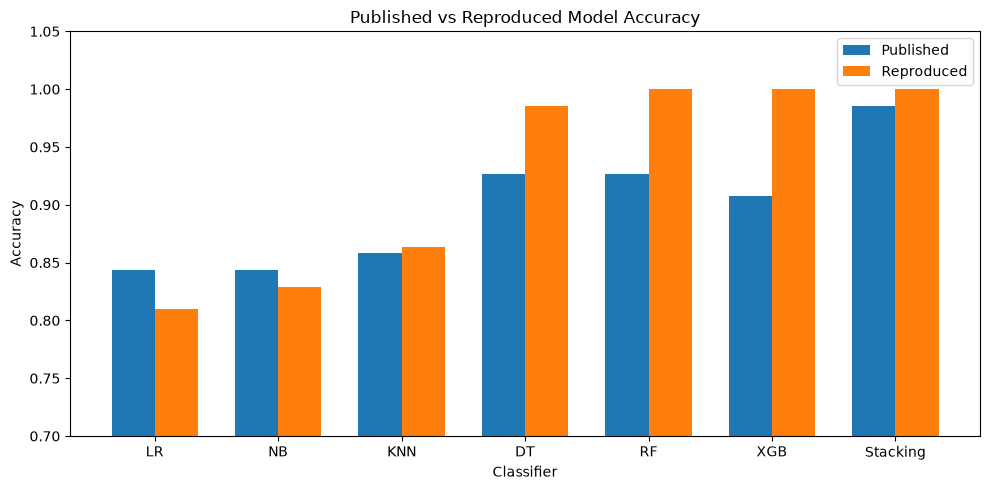

In [17]:
import matplotlib.pyplot as plt
import numpy as np

models = ["LR", "NB", "KNN", "DT", "RF", "XGB", "Stacking"]

paper_accuracy = [
    0.8439, 0.8439, 0.8585,
    0.9268, 0.9268, 0.9073, 0.9853
]

my_accuracy = [
    lr_accuracy,
    nb_accuracy,
    knn_accuracy,
    dt_accuracy,
    rf_accuracy,
    xgb_accuracy,
    stack_accuracy
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(x - width/2, paper_accuracy, width, label="Published")
plt.bar(x + width/2, my_accuracy, width, label="Reproduced")

plt.xlabel("Classifier")
plt.ylabel("Accuracy")
plt.title("Published vs Reproduced Model Accuracy")
plt.xticks(x, models)
plt.ylim(0.7, 1.05)
plt.legend()

plt.tight_layout()
plt.show()

# Part 2 – Proposed Machine Learning Solution

## Identified Limitation and Proposed Improvement

During the Part 1 reproduction, I found that the dataset contained a large number of exact duplicate records. The original 1,025-row dataset contained only 302 unique rows when exact duplicates were removed.

Because Part 1 used a random row-level train-test split, duplicate copies of the same feature record could be placed in both sets. My diagnostic analysis showed that 202 of the 205 test records (98.54%) had an identical feature record in the training set.

This became particularly important when interpreting the reproduced results. Decision Tree achieved 98.54% accuracy, while Random Forest, XGBoost, and the stacking ensemble all achieved 100% accuracy.

For Part 2, I therefore redesign the experimental protocol rather than simply changing the classifier. The proposed approach prevents exact duplicate feature records from being shared between the training and testing sets. The aim is to evaluate the models on test feature records that are genuinely separated from those used for training and determine whether the very high Part 1 performance remains under this stricter evaluation setup.

## Duplicate-Safe Dataset Preparation

To prevent identical records from appearing in both the training and testing sets, I first created a duplicate-safe version of the dataset by retaining one copy of each exact row.

The original dataset is kept unchanged as `df`, meaning the Part 1 reproduction remains reproducible. A new DataFrame is created specifically for the proposed Part 2 experiment.

After duplicate removal, I again separate the predictor attributes from the target variable before constructing the new training and testing sets.

In [20]:
# Create a separate dataset for the Part 2 experiment
df_part2 = df.drop_duplicates().reset_index(drop=True)

print("Original dataset rows:", len(df))
print("Part 2 unique rows:", len(df_part2))
print("Duplicates removed:", len(df) - len(df_part2))

print("\nPart 2 dataset shape:", df_part2.shape)

print("\nTarget distribution:")
print(df_part2["target"].value_counts())

Original dataset rows: 1025
Part 2 unique rows: 302
Duplicates removed: 723

Part 2 dataset shape: (302, 14)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64


In [21]:
X_part2 = df_part2.drop("target", axis=1)
y_part2 = df_part2["target"]

print("Part 2 feature shape:", X_part2.shape)
print("Part 2 target shape:", y_part2.shape)

print("\nTarget distribution:")
print(y_part2.value_counts())

Part 2 feature shape: (302, 13)
Part 2 target shape: (302,)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64


## Duplicate-Safe Train-Test Split

A new train-test split was created using only the duplicate-safe dataset. I used the same 80:20 proportion and fixed random state as Part 1 so that the main experimental settings remain consistent while the key change is the handling of duplicate records.

Stratification was again used to preserve the target-class distribution as closely as possible between the training and testing sets.

This creates a stricter evaluation than Part 1 because an exact duplicated row can no longer appear in both the training and testing sets.

In [22]:
X_train_p2, X_test_p2, y_train_p2, y_test_p2 = train_test_split(
    X_part2,
    y_part2,
    test_size=0.20,
    random_state=42,
    stratify=y_part2
)

print("Part 2 training features:", X_train_p2.shape)
print("Part 2 testing features:", X_test_p2.shape)

print("\nTraining target distribution:")
print(y_train_p2.value_counts())

print("\nTesting target distribution:")
print(y_test_p2.value_counts())

Part 2 training features: (241, 13)
Part 2 testing features: (61, 13)

Training target distribution:
target
1    131
0    110
Name: count, dtype: int64

Testing target distribution:
target
1    33
0    28
Name: count, dtype: int64


## Verification of Train-Test Separation

The main purpose of the proposed protocol is to prevent identical feature records from appearing in both the training and testing sets.

Therefore, I repeated the same overlap test used during Part 1. If the proposed preparation works correctly, none of the Part 2 testing feature records should have an identical copy in the training set.

In [23]:
overlap_count_p2 = 0

for _, test_row in X_test_p2.iterrows():
    match = (X_train_p2 == test_row).all(axis=1)

    if match.any():
        overlap_count_p2 += 1

print("Part 2 test records:", len(X_test_p2))
print(
    "Test records also appearing in training:",
    overlap_count_p2
)

print(
    "Percentage of test set overlapping with training:",
    round((overlap_count_p2 / len(X_test_p2)) * 100, 2),
    "%"
)

Part 2 test records: 61
Test records also appearing in training: 0
Percentage of test set overlapping with training: 0.0 %


## Preprocessing the Proposed Dataset

After creating the new duplicate-safe training and testing sets, I repeated the feature scaling stage using only the Part 2 training data.

A new scaler was fitted to the Part 2 training set and then applied to the Part 2 testing set. This keeps the proposed experiment independent from the preprocessing performed during Part 1 and prevents information from the previous experimental setup being reused in the new evaluation.

In [25]:
# Create a new scaler specifically for Part 2
scaler_p2 = StandardScaler()

X_train_p2_scaled = scaler_p2.fit_transform(X_train_p2)
X_test_p2_scaled = scaler_p2.transform(X_test_p2)

print("Part 2 training data shape after scaling:",
      X_train_p2_scaled.shape)

print("Part 2 testing data shape after scaling:",
      X_test_p2_scaled.shape)

print("\nFirst 3 scaled training records:")
print(X_train_p2_scaled[:3])

Part 2 training data shape after scaling: (241, 13)
Part 2 testing data shape after scaling: (61, 13)

First 3 scaled training records:
[[ 1.42194408 -1.44559455  0.98649276 -0.97304069  5.88290757 -0.39831375
  -1.00805864  0.4082403  -0.65271395  0.52726339 -0.69712735 -0.72271635
   1.07583844]
 [-0.46584105  0.6917569  -0.95428075  0.75650697 -0.88569606 -0.39831375
  -1.00805864 -1.10470453  1.53206469 -0.08323307 -0.69712735 -0.72271635
   1.07583844]
 [ 0.42252843  0.6917569  -0.95428075 -0.19772622 -0.58817502 -0.39831375
  -1.00805864 -0.88221265  1.53206469  1.05054606 -0.69712735  2.13260562
   1.07583844]]




To evaluate the effect of the proposed experimental protocol, I trained the same six individual classifiers used in the Part 1 reproduction: Logistic Regression, Naive Bayes, KNN, Decision Tree, Random Forest, and XGBoost.

Using the same classifier types allows the main methodological difference between Part 1 and Part 2 to remain the treatment of duplicate records and the resulting separation between training and testing data.



In [26]:
# Part 2 models
models_p2 = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    )
}

part2_results = []

for name, model in models_p2.items():

    # Train model
    model.fit(X_train_p2_scaled, y_train_p2)

    # Predictions
    predictions = model.predict(X_test_p2_scaled)
    probabilities = model.predict_proba(X_test_p2_scaled)[:, 1]

    # Evaluation metrics
    accuracy = accuracy_score(y_test_p2, predictions)
    precision = precision_score(y_test_p2, predictions)
    recall = recall_score(y_test_p2, predictions)
    f1 = f1_score(y_test_p2, predictions)
    auc = roc_auc_score(y_test_p2, probabilities)

    part2_results.append([
        name,
        accuracy,
        precision,
        recall,
        f1,
        auc
    ])

# Create results table
part2_results_df = pd.DataFrame(
    part2_results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "AUC"
    ]
)

print(part2_results_df.round(4).to_string(index=False))

              Model  Accuracy  Precision  Recall     F1    AUC
Logistic Regression    0.8033     0.8000  0.8485 0.8235 0.8712
        Naive Bayes    0.7869     0.8333  0.7576 0.7937 0.8842
                KNN    0.7869     0.7778  0.8485 0.8116 0.8377
      Decision Tree    0.8033     0.8182  0.8182 0.8182 0.8019
      Random Forest    0.7541     0.7647  0.7879 0.7761 0.8588
            XGBoost    0.7213     0.7353  0.7576 0.7463 0.8323


## Stacking Ensemble Under the Proposed Protocol

The selected paper's main proposed approach is a 5-fold stacking ensemble. Therefore, I also evaluated the stacking approach using the duplicate-safe Part 2 training and testing data.

I kept the stacking structure consistent with my Part 1 reproduction, including the same six base classifiers, 5-fold validation, and Logistic Regression as the documented meta-classifier assumption. This allows the effect of the changed experimental protocol to be examined without introducing a different ensemble design.

The resulting stacking model is evaluated using Accuracy, Precision, Recall, F1 Score, and AUC, consistent with the previous experiments.

In [28]:
# 5-fold validation for Part 2
cv_p2 = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Same base classifiers used in Part 1
base_models_p2 = [
    ("lr", LogisticRegression(max_iter=1000)),
    ("dt", DecisionTreeClassifier(random_state=42)),
    ("rf", RandomForestClassifier(random_state=42)),
    ("xgb", XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    )),
    ("nb", GaussianNB()),
    ("knn", KNeighborsClassifier())
]

# Same meta-classifier assumption as Part 1
stacking_model_p2 = StackingClassifier(
    estimators=base_models_p2,
    final_estimator=LogisticRegression(max_iter=1000),
    cv=cv_p2
)

# Train
stacking_model_p2.fit(X_train_p2_scaled, y_train_p2)

# Predict
stack_predictions_p2 = stacking_model_p2.predict(X_test_p2_scaled)
stack_probabilities_p2 = stacking_model_p2.predict_proba(
    X_test_p2_scaled
)[:, 1]

# Metrics
stack_accuracy_p2 = accuracy_score(
    y_test_p2, stack_predictions_p2
)

stack_precision_p2 = precision_score(
    y_test_p2, stack_predictions_p2
)

stack_recall_p2 = recall_score(
    y_test_p2, stack_predictions_p2
)

stack_f1_p2 = f1_score(
    y_test_p2, stack_predictions_p2
)

stack_auc_p2 = roc_auc_score(
    y_test_p2, stack_probabilities_p2
)

print("Part 2 - 5-Fold Stacking Results")
print("--------------------------------")
print("Accuracy :", round(stack_accuracy_p2, 4))
print("Precision:", round(stack_precision_p2, 4))
print("Recall   :", round(stack_recall_p2, 4))
print("F1 Score :", round(stack_f1_p2, 4))
print("AUC      :", round(stack_auc_p2, 4))

Part 2 - 5-Fold Stacking Results
--------------------------------
Accuracy : 0.8033
Precision: 0.8182
Recall   : 0.8182
F1 Score : 0.8182
AUC      : 0.882


## Five-Fold Cross-Validation

The duplicate-safe dataset contains fewer observations than the original dataset because repeated records were removed. Therefore, relying only on one 80:20 train-test split could make the evaluation sensitive to the particular observations selected for testing.

To provide additional empirical evidence, I used 5-fold stratified cross-validation on the duplicate-safe dataset. Stratification maintains the target-class distribution across the folds.

Accuracy, Precision, Recall, F1 Score, and AUC were calculated across the five folds. I report the mean and standard deviation to show both average model performance and variation between folds.

In [29]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

cv_evaluation = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "auc": "roc_auc"
}

cv_results = []

for name, model in models_p2.items():

    # Scaling is fitted separately inside each CV fold
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    scores = cross_validate(
        pipeline,
        X_part2,
        y_part2,
        cv=cv_evaluation,
        scoring=scoring
    )

    cv_results.append([
        name,
        scores["test_accuracy"].mean(),
        scores["test_accuracy"].std(),
        scores["test_precision"].mean(),
        scores["test_recall"].mean(),
        scores["test_f1"].mean(),
        scores["test_auc"].mean()
    ])

cv_results_df = pd.DataFrame(
    cv_results,
    columns=[
        "Model",
        "Mean Accuracy",
        "Accuracy Std",
        "Mean Precision",
        "Mean Recall",
        "Mean F1",
        "Mean AUC"
    ]
)

print(cv_results_df.round(4).to_string(index=False))

              Model  Mean Accuracy  Accuracy Std  Mean Precision  Mean Recall  Mean F1  Mean AUC
Logistic Regression         0.8312        0.0281          0.8380       0.8655   0.8454    0.9045
        Naive Bayes         0.8079        0.0372          0.8197       0.8354   0.8227    0.8934
                KNN         0.8081        0.0274          0.8031       0.8598   0.8295    0.8837
      Decision Tree         0.7715        0.0424          0.7794       0.8110   0.7927    0.7674
      Random Forest         0.8214        0.0329          0.8316       0.8473   0.8363    0.9066
            XGBoost         0.8114        0.0525          0.8257       0.8290   0.8243    0.8734


##  Comparison with the Published Study and Part 1 Reproduction

The final stage compares three sets of results:

1. the results reported in the selected paper;
2. my Part 1 reproduction using the original dataset and random row-level split; and
3. my Part 2 results using the duplicate-safe experimental protocol.

This comparison is used to examine how model performance changes when identical records are prevented from appearing across the training and testing sets. The Part 2 results should therefore not be interpreted only in terms of whether accuracy increased or decreased. The main purpose of the proposed methodology is to provide a stricter separation between training and testing observations and examine whether the very high Part 1 results remain under this condition.

In [30]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Naive Bayes",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "Stacking"
    ],

    "Published": [
        0.8439,
        0.8439,
        0.8585,
        0.9268,
        0.9268,
        0.9073,
        0.9853
    ],

    "Part 1 Reproduction": [
        lr_accuracy,
        nb_accuracy,
        knn_accuracy,
        dt_accuracy,
        rf_accuracy,
        xgb_accuracy,
        stack_accuracy
    ],

    "Part 2 Proposed": [
        0.8033,
        0.7869,
        0.7869,
        0.8033,
        0.7541,
        0.7213,
        stack_accuracy_p2
    ]
})

print(final_comparison.round(4).to_string(index=False))

              Model  Published  Part 1 Reproduction  Part 2 Proposed
Logistic Regression     0.8439               0.8098           0.8033
        Naive Bayes     0.8439               0.8293           0.7869
                KNN     0.8585               0.8634           0.7869
      Decision Tree     0.9268               0.9854           0.8033
      Random Forest     0.9268               1.0000           0.7541
            XGBoost     0.9073               1.0000           0.7213
           Stacking     0.9853               1.0000           0.8033


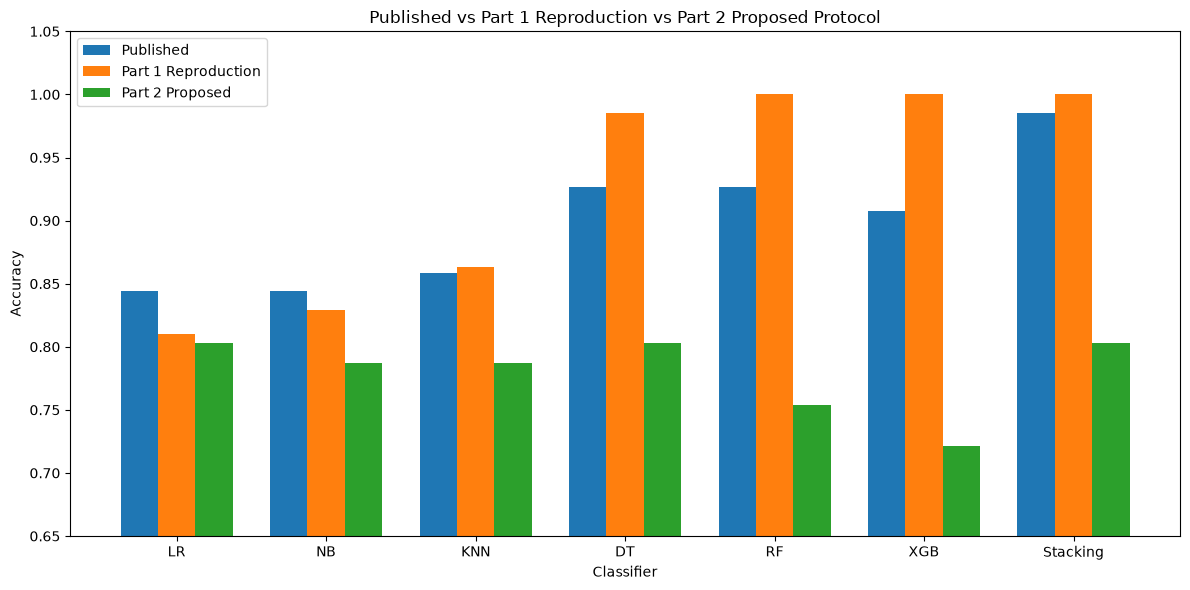

In [31]:
models = final_comparison["Model"]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(12, 6))

plt.bar(
    x - width,
    final_comparison["Published"],
    width,
    label="Published"
)

plt.bar(
    x,
    final_comparison["Part 1 Reproduction"],
    width,
    label="Part 1 Reproduction"
)

plt.bar(
    x + width,
    final_comparison["Part 2 Proposed"],
    width,
    label="Part 2 Proposed"
)

plt.xlabel("Classifier")
plt.ylabel("Accuracy")
plt.title(
    "Published vs Part 1 Reproduction vs Part 2 Proposed Protocol"
)

plt.xticks(
    x,
    ["LR", "NB", "KNN", "DT", "RF", "XGB", "Stacking"]
)

plt.ylim(0.65, 1.05)
plt.legend()

plt.tight_layout()
plt.show()

In [32]:
stack_row = pd.DataFrame({
    "Model": ["Stacking"],
    "Accuracy": [stack_accuracy_p2],
    "Precision": [stack_precision_p2],
    "Recall": [stack_recall_p2],
    "F1": [stack_f1_p2],
    "AUC": [stack_auc_p2]
})

part2_complete_results = pd.concat(
    [part2_results_df, stack_row],
    ignore_index=True
)

print("Part 2 Complete Results")
print("-----------------------")
print(
    part2_complete_results
    .round(4)
    .to_string(index=False)
)

Part 2 Complete Results
-----------------------
              Model  Accuracy  Precision  Recall     F1    AUC
Logistic Regression    0.8033     0.8000  0.8485 0.8235 0.8712
        Naive Bayes    0.7869     0.8333  0.7576 0.7937 0.8842
                KNN    0.7869     0.7778  0.8485 0.8116 0.8377
      Decision Tree    0.8033     0.8182  0.8182 0.8182 0.8019
      Random Forest    0.7541     0.7647  0.7879 0.7761 0.8588
            XGBoost    0.7213     0.7353  0.7576 0.7463 0.8323
           Stacking    0.8033     0.8182  0.8182 0.8182 0.8820
